# Assignment 2
## Group A: Polynomial Regression
### Ivan Bibat
#### L00167791@atu.ie

## What is polynomial regression ?
Polynomial regression is a form of linear regression where the relationship between the independent variable x and dependent variable y are modeled as an nth order polynomial.

Polynomial regression fits a non-linear relationship between the value of x and the corresponding conditional mean of y.

1. Install required dependencies

In [1]:
%pip install -q numpy pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


2. Import necessary packages

In [2]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline

3. Read the data

In [3]:
df = pd.read_csv("/Users/ivanbibat/Documents/GitHub/machine-learning-notebooks/data/co2_mm_mlo.csv", comment = "#")

In [4]:
# Display basic information about the dataset
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 823 entries, 0 to 822
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   year            823 non-null    int64  
 1   month           823 non-null    int64  
 2   decimal date    823 non-null    float64
 3   average         823 non-null    float64
 4   deseasonalized  823 non-null    float64
 5   ndays           823 non-null    int64  
 6   sdev            823 non-null    float64
 7   unc             823 non-null    float64
dtypes: float64(5), int64(3)
memory usage: 51.6 KB
None


In [5]:
# Summary statistics for numerical columns
print(df.describe())

              year       month  decimal date     average  deseasonalized  \
count   823.000000  823.000000    823.000000  823.000000      823.000000   
mean   1991.958688    6.495747   1992.457736  361.439101      361.431786   
std      19.812337    3.444685     19.811122   33.511832       33.451725   
min    1958.000000    1.000000   1958.202700  312.420000      314.440000   
25%    1975.000000    4.000000   1975.333350  331.285000      330.915000   
50%    1992.000000    6.000000   1992.458300  356.380000      356.500000   
75%    2009.000000    9.000000   2009.583350  387.845000      387.825000   
max    2026.000000   12.000000   2026.708300  432.340000      429.550000   

            ndays        sdev         unc  
count  823.000000  823.000000  823.000000  
mean    19.165249   -1.991592   -0.084593  
std     11.810524    4.478122    0.508127  
min     -1.000000   -9.990000   -0.990000  
25%     14.500000    0.210000    0.080000  
50%     25.000000    0.400000    0.150000  
75%    

In [6]:
# Check for missing values in the dataset
print(df.isnull().sum())

year              0
month             0
decimal date      0
average           0
deseasonalized    0
ndays             0
sdev              0
unc               0
dtype: int64


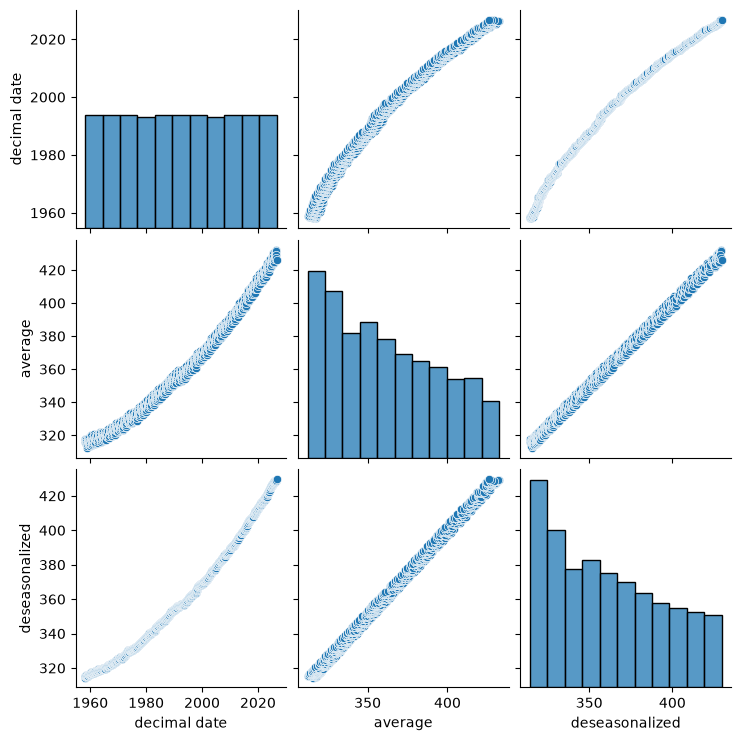

In [7]:
'''

Pairplots are used to visualize relationships between numerical variables.
Each plot compares two variables, and the diagonal displays histograms.

'''

sns.pairplot(
    df,  
    vars=
    [
        "decimal date",
        "average",
        "deseasonalized",
    ]
)
plt.show()

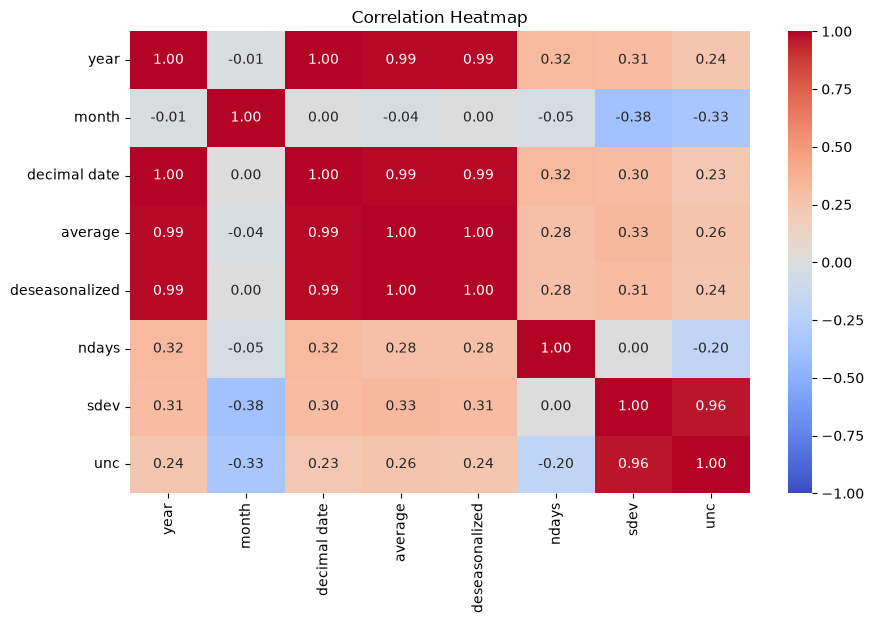

In [8]:
'''
A correlation heatmap displays the relationships (correlations) between variables.
Values close to 1 or -1 indicate strong correlations.
Values close to 0 indicate weak or no correlations.               
'''

cols = ["ndays", "sdev", "unc"]
df[cols] = df[cols].mask(df[cols] < 0, np.nan)

correlation_matrix = df.corr()
plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, center=0)
plt.title("Correlation Heatmap")
plt.show()


In [9]:
df.head()

,year,month,decimal date,average,deseasonalized,ndays,sdev,unc
0,1958,3,1958.2027,315.71,314.44,NaN,NaN,NaN
1,1958,4,1958.2877,317.45,315.16,NaN,NaN,NaN
2,1958,5,1958.3699,317.51,314.69,NaN,NaN,NaN
3,1958,6,1958.4548,317.27,315.15,NaN,NaN,NaN
4,1958,7,1958.5370,315.87,315.20,NaN,NaN,NaN


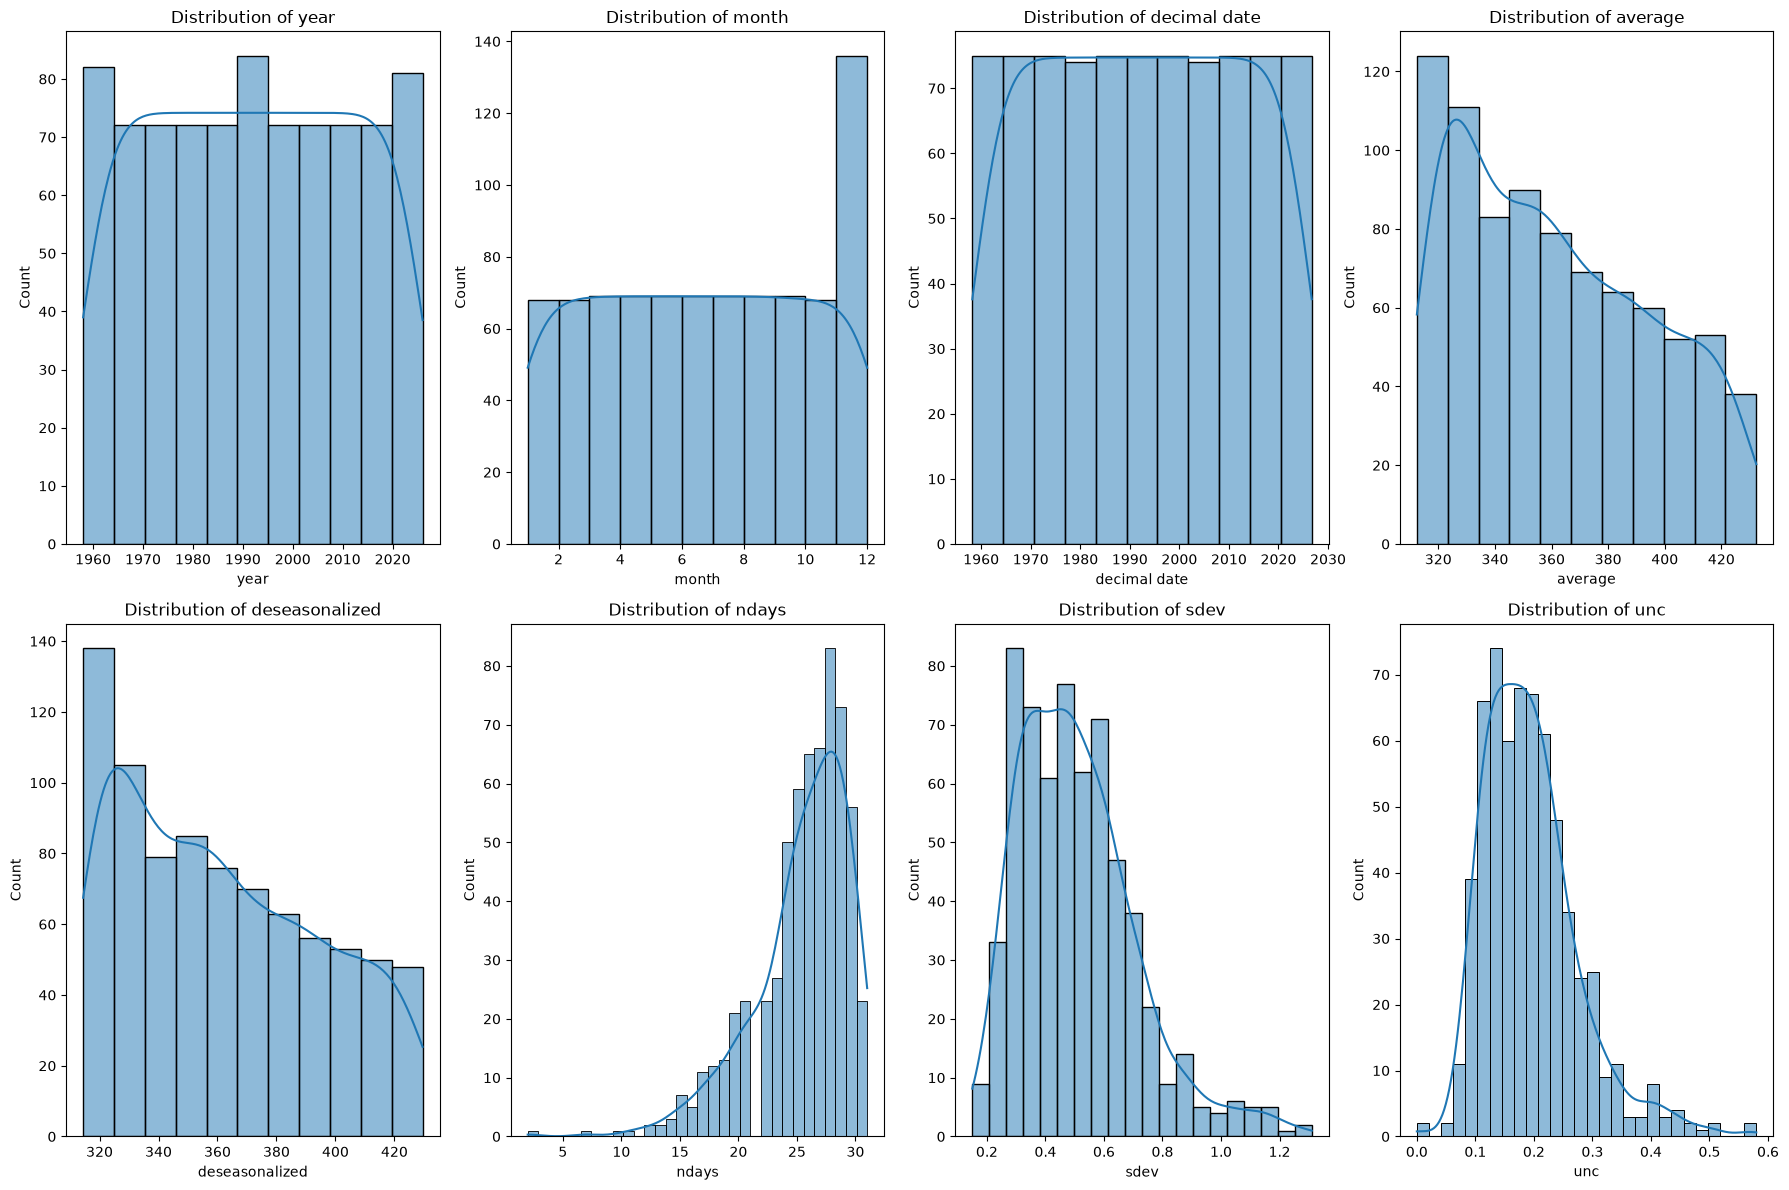

In [10]:
'''
Data distribution plots, such as histograms, help visualize the distribution of individual numerical columns.
These plots can reveal the data's skewness and central tendencies.
'''
plt.figure(figsize=(18, 12))
numerical_columns = df.columns
for i, col in enumerate(numerical_columns):
    plt.subplot(2, 4, i + 1)
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

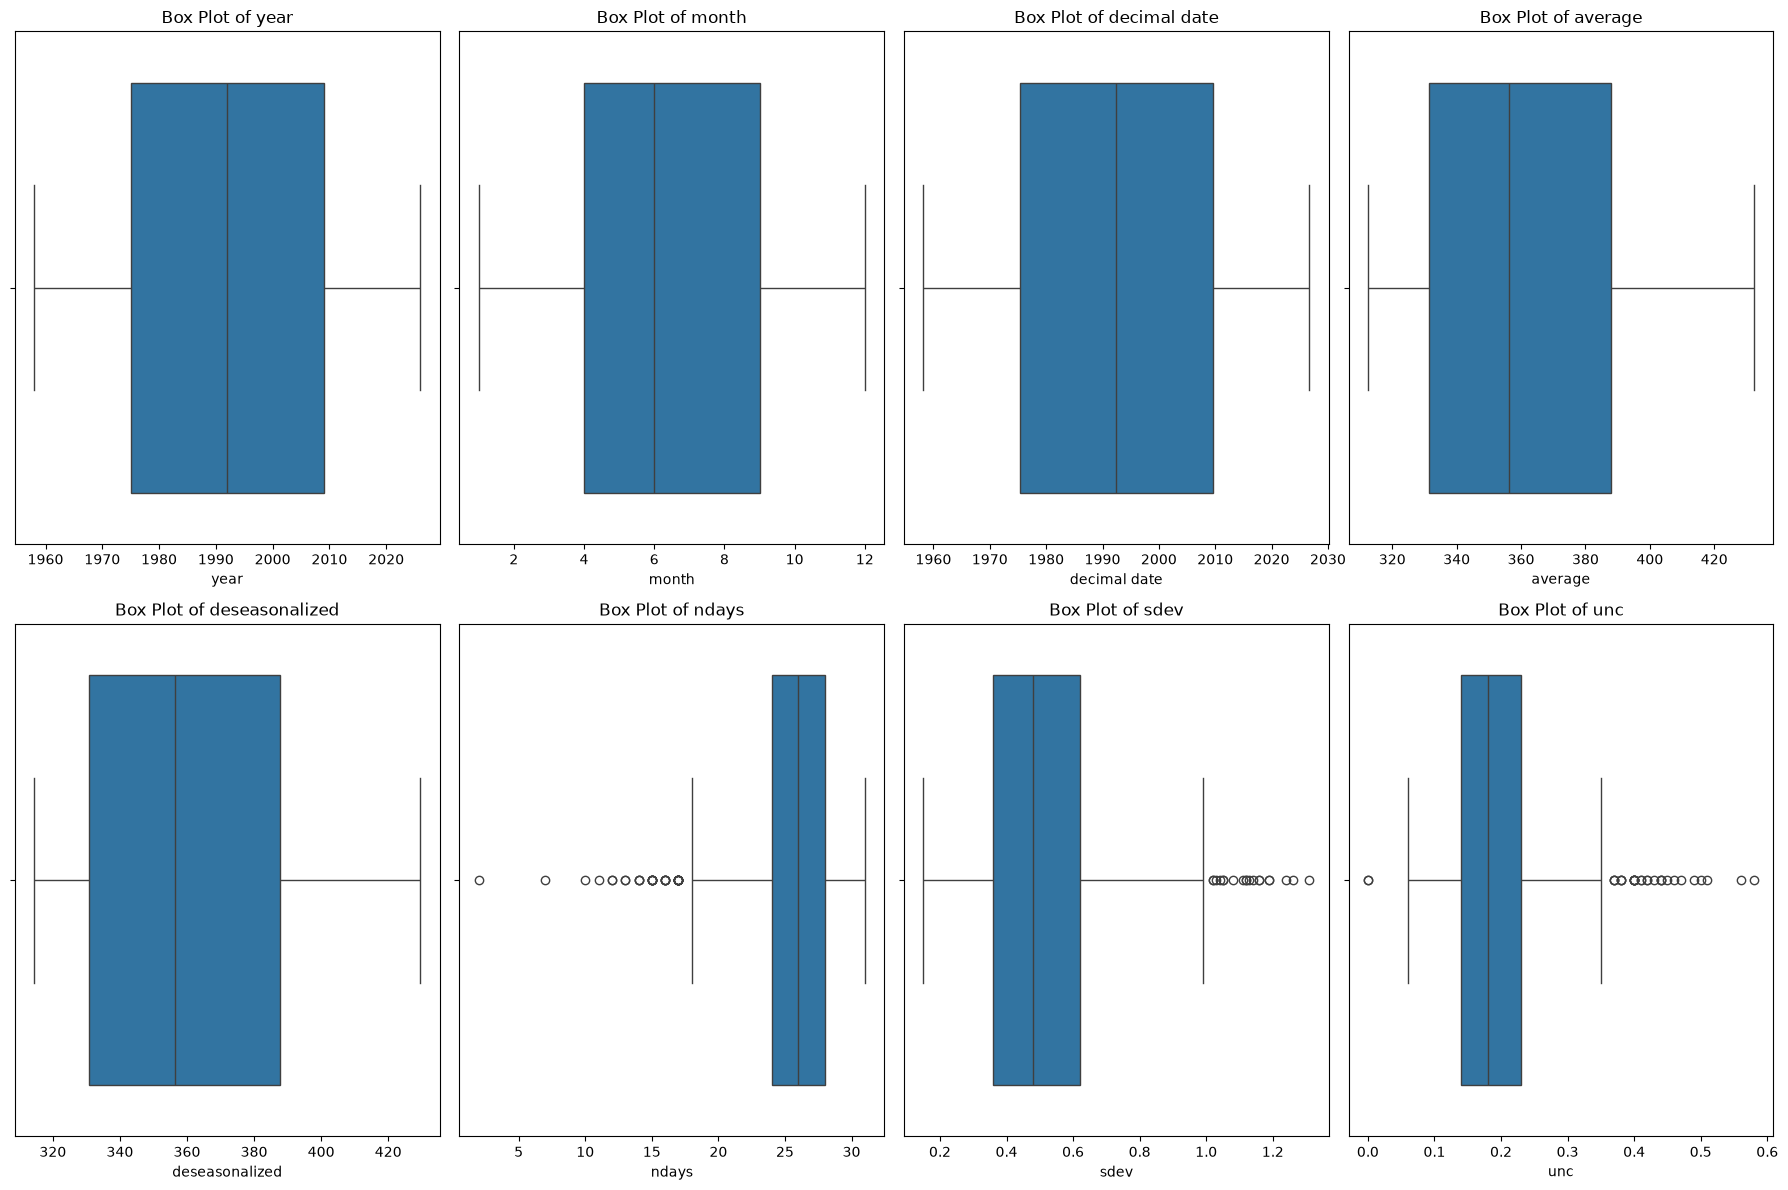

In [11]:
# Box plots provide a way to visualize the spread and presence of outliers in numerical columns.

plt.figure(figsize=(18, 12))
for i, col in enumerate(numerical_columns):
    plt.subplot(2, 4, i + 1)
    sns.boxplot(x=df[col])
    plt.title(f'Box Plot of {col}')
plt.tight_layout()
plt.show()

## 4. Preparing the dataset

One input and one output:
- Input (x): time t = years since 1958,
- Output (y): the deseasonalised CO2 value in ppm

In [12]:
data = df[['decimal date', 'average', 'deseasonalized']].copy()

data['t'] = data['decimal date'] - 1958

data.head()

,decimal date,average,deseasonalized,t
0,1958.2027,315.71,314.44,0.2027
1,1958.2877,317.45,315.16,0.2877
2,1958.3699,317.51,314.69,0.3699
3,1958.4548,317.27,315.15,0.4548
4,1958.5370,315.87,315.20,0.5370


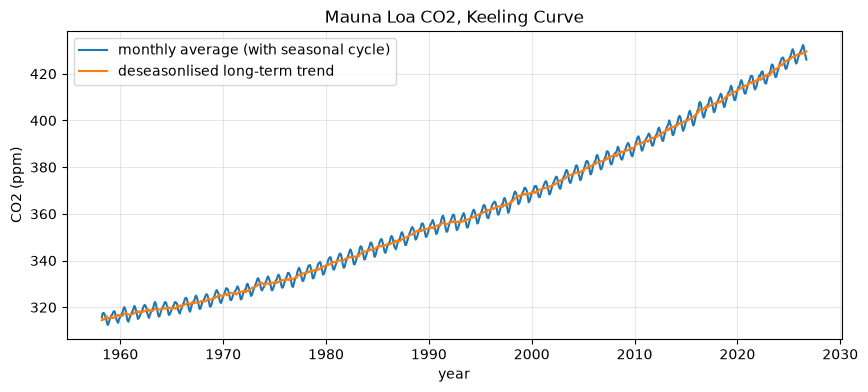

In [13]:
plt.figure(figsize = (10,4))

plt.plot(data['decimal date'], data['average'], label = 'monthly average (with seasonal cycle)')

plt.xlabel('year')
plt.ylabel('CO2 (ppm)')

plt.title('Mauna Loa CO2, Keeling Curve')

plt.plot(data['decimal date'], data['deseasonalized'], label = 'deseasonlised long-term trend')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Why use `t` instead of year?**

- Polynomial Regression raises x to powers. If the raw year is used instead, the number grows very large. With t (0-68), 68^2 is 4624, keeping the values managable. 2026^2 is over 4 million.

**Why model 'deseasonalised' instead of 'average'?**

- The monthly average zigzags per year because plants in the northern hemisphere absorb CO2 during the summer then release it in the winter.

- By deseasonalising the data (NOAA) in `deseasonalized`, the yearly cycle is removed, revealing the long-term trend, which the polynomial model should learn.


**The plot**

- The curve bends upwards, indicating that CO2 rises faster each decade. As linear regression is a straight line, polynomial is the better choice for this data.

## 5. Splitting the data by time

With time-series, splitting rows randomly is not ideal as a model could be trained on 2025 data then tested on 2024, 'seeing the future'.

Instead, the data is split in time order:

- Training - 1958-2005 ( fitting the polynomial coefficients)
- Validation - 2006-2015 (Picking the best polynomial degree)
- Test - 2016-2026 (Final check on unseen data during training)

In [14]:
train = data[data['decimal date'] < 2006]
val = data[(data['decimal date'] >= 2006) & (data['decimal date'] < 2016)]
test = data[(data['decimal date'] >= 2016)]

In [15]:
X_train, y_train = train[['t']], train['deseasonalized']
X_val, y_val = val[['t']], val['deseasonalized']
X_test, y_test = test[['t']], test['deseasonalized']

print(
    f"Training rows: {len(train)}\n"
    f"Validation rows: {len(val)}\n"
    f"Test rows: {len(test)}\n"
)


Training rows: 574
Validation rows: 120
Test rows: 129



## 6. How Polynomial Regression Works

Polynomial Regression works in two steps:
1. **`PolynomialFeatures`** turns the single input `t` into new columns t&1, ..., t^n where *n* is the degree.
2. **`LinearRegression`**  fits an ordinary linear model on all columns, using least-squares to find the coefficients that minimise the sum of squared errors.

In [16]:
example = pd.DataFrame({'t': [0,10,50]})

poly = PolynomialFeatures(degree=3, include_bias = False)
pd.DataFrame(poly.fit_transform(example), columns=poly.get_feature_names_out())

,t,t^2,t^3
0,0.0,0.0,0.0
1,10.0,100.0,1000.0
2,50.0,2500.0,125000.0


In [17]:
def make_poly_model(degree, scale=True):

    steps = [StandardScaler()] if scale else []
    steps += [PolynomialFeatures(degree=degree, include_bias=False), LinearRegression()]
    return make_pipeline(*steps)


def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


## 7. Choosing the degree: underfitting vs overfitting

- One model is trained for each degree from 1 to 8 on the training years. Each one's RMSE is measured on the training years and the validation years.
- The best degree is the one with the lowest validation error, showing how well the model does on unseen data.

In [18]:
degrees = range(1, 9)
results = []

for d in degrees:
    model = make_poly_model(d).fit(X_train, y_train)
    results.append({
        'degree': d,
        'train RMSE (ppm)': rmse(y_train, model.predict(X_train)),
        'validation RMSE (ppm)': rmse(y_val, model.predict(X_val)),
    })

results = pd.DataFrame(results).set_index('degree')
best_degree = results['validation RMSE (ppm)'].idxmin()

print(f"Best degree on validation data: {best_degree}")
results.round(3)


Best degree on validation data: 2


,train RMSE (ppm),validation RMSE (ppm)
degree,,
1,2.156,8.378
2,0.771,0.523
3,0.680,3.289
4,0.596,2.188
5,0.516,12.783
6,0.511,7.333
7,0.494,16.202
8,0.484,55.681


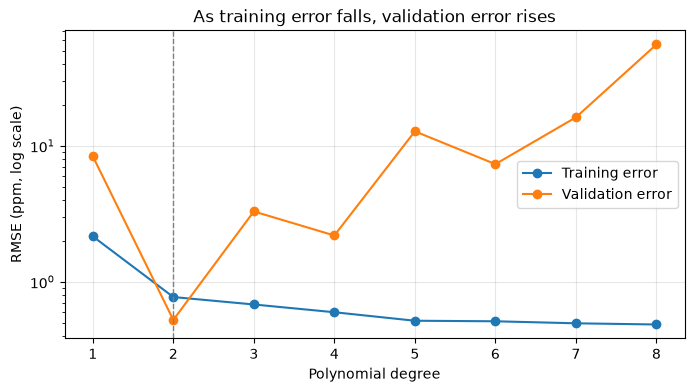

In [19]:
plt.figure(figsize=(8, 4))
plt.plot(results.index, results['train RMSE (ppm)'], marker='o', label='Training error')
plt.plot(results.index, results['validation RMSE (ppm)'], marker='o', label='Validation error')
plt.axvline(best_degree, color='grey', linestyle='--', linewidth=1)
plt.yscale('log')
plt.xlabel('Polynomial degree')
plt.ylabel('RMSE (ppm, log scale)')
plt.title('As training error falls, validation error rises')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


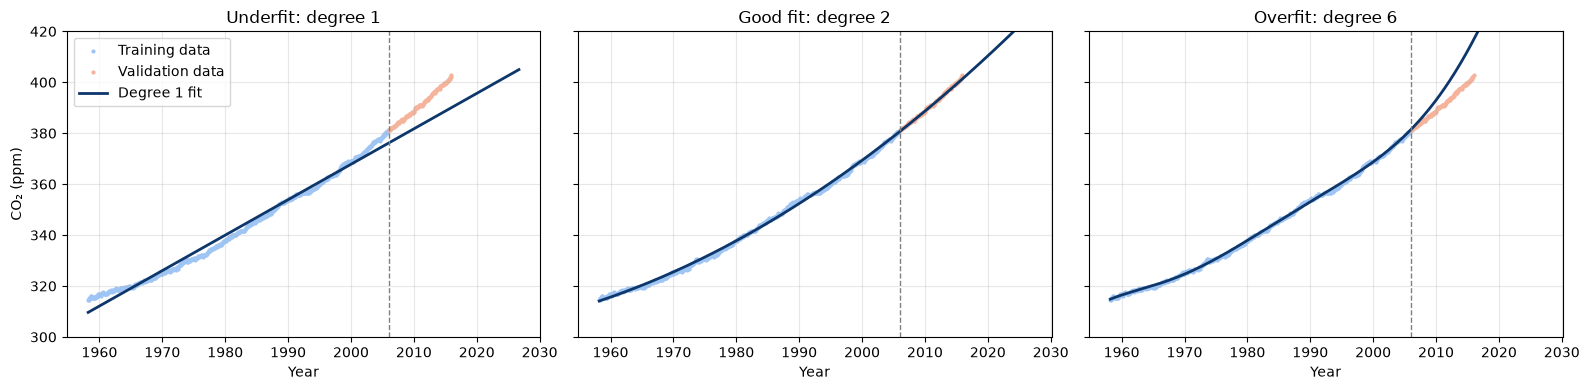

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

for ax, d, label in zip(axes, [1, best_degree, 6], ['Underfit', 'Good fit', 'Overfit']):
    model = make_poly_model(d).fit(X_train, y_train)
    ax.scatter(train['decimal date'], y_train, s=4, color='#9ec5f4', label='Training data')
    ax.scatter(val['decimal date'], y_val, s=4, color='#f4b39a', label='Validation data')
    ax.plot(data['decimal date'], model.predict(data[['t']]), color='#0d366b', linewidth=2, label=f'Degree {d} fit')
    ax.axvline(2006, color='grey', linestyle='--', linewidth=1)
    ax.set_title(f'{label}: degree {d}')
    ax.set_xlabel('Year')
    ax.set_ylim(300, 420)
    ax.grid(alpha=0.3)

axes[0].set_ylabel('CO₂ (ppm)')
axes[0].legend()
plt.tight_layout()
plt.show()


- Degree 1: The fit of the line is a straight line, not fitting to the pattern in the validation data.
- Degree 2: The model fits close to the pattern in the validation data, showing that the model has learned the patterns in the training data
- Degree 6: The model is curving too far in the validation data, indicating that the model has overfit (learned the noise) to the training data.

If a model is too simple, it misses the pattern in the data (high bias).
If it's too complex, it overfits to the noise (high variance).

## 8. Final Model, testing on new, unseen data.

The chosen degree is retrained on all data up to 2015, then tested on the test set(2016-2026).

For degree 2, the numbers stay small, meaning that the scaler isn't needed. Turning it off returns identical predictions and the coefficients can be read in ppm and years.

In [21]:
dev = data[data['decimal date'] < 2016]

final_model = make_poly_model(best_degree, scale=False).fit(dev[['t']], dev['deseasonalized'])
test_pred = final_model.predict(X_test)

print(f"Test RMSE: {rmse(y_test, test_pred):.2f} ppm")
print(f"Test R²:   {r2_score(y_test, test_pred):.3f}")

# Read the coefficients out of the linear regression step of the pipeline
lin = final_model.named_steps['linearregression']
b0, (b1, b2) = lin.intercept_, lin.coef_
print(f"\nFitted equation:  CO₂ = {b0:.2f} + {b1:.4f}·t + {b2:.5f}·t²   (t = years since 1958)")


Test RMSE: 2.18 ppm
Test R²:   0.922

Fitted equation:  CO₂ = 314.06 + 0.8073·t + 0.01218·t²   (t = years since 1958)


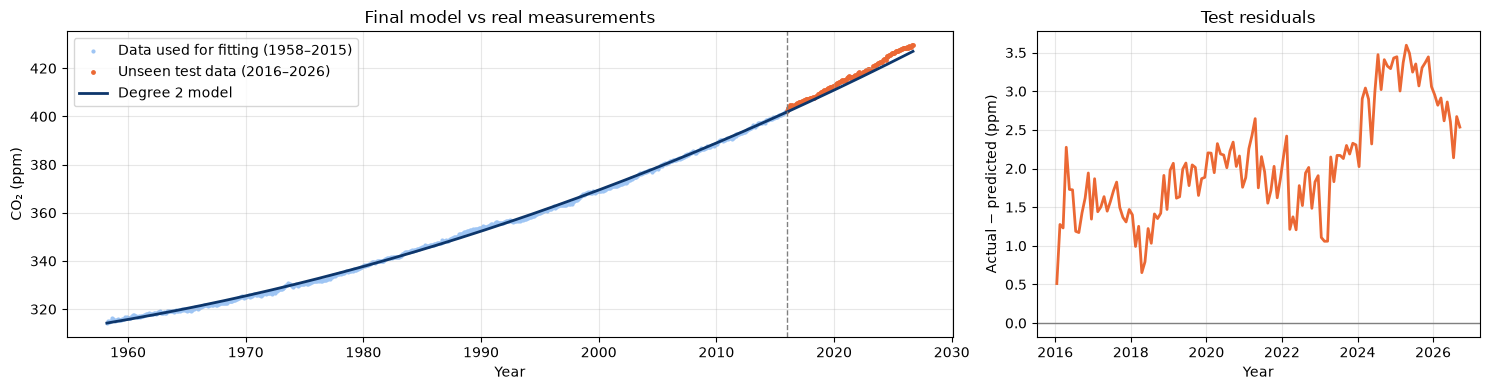

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={'width_ratios': [2, 1]})

# Left: the model against all the real data
ax1.scatter(dev['decimal date'], dev['deseasonalized'], s=4, color='#9ec5f4', label='Data used for fitting (1958–2015)')
ax1.scatter(test['decimal date'], y_test, s=6, color='#eb6834', label='Unseen test data (2016–2026)')
ax1.plot(data['decimal date'], final_model.predict(data[['t']]), color='#0d366b', linewidth=2, label=f'Degree {best_degree} model')
ax1.axvline(2016, color='grey', linestyle='--', linewidth=1)
ax1.set_xlabel('Year')
ax1.set_ylabel('CO₂ (ppm)')
ax1.set_title('Final model vs real measurements')
ax1.legend()
ax1.grid(alpha=0.3)

# Right: residuals = how far off the model is in each test month
residuals = y_test - test_pred   # positive = real CO₂ is higher than predicted
ax2.plot(test['decimal date'], residuals, color='#eb6834', linewidth=2)
ax2.axhline(0, color='grey', linewidth=1)
ax2.set_xlabel('Year')
ax2.set_ylabel('Actual − predicted (ppm)')
ax2.set_title('Test residuals')
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()


The slope of a curve is how fast it's rising at that moment.

In [23]:
for year in [1960, 1990, 2025]:
    t = year - 1958
    print(f"Modelled growth rate in {year}: {b1 + 2 * b2 * t:.2f} ppm per year")


Modelled growth rate in 1960: 0.86 ppm per year
Modelled growth rate in 1990: 1.59 ppm per year
Modelled growth rate in 2025: 2.44 ppm per year


### Understanding the final model

- 1. Accuracy
RMSE 2.18 ppm against values > 400 ppm, and R^2 of 0.922.
The RMSE is the avg. distance between predicted and actual values. 2.18 ppm is a very small error compared to the 400ppm values, indicating high accuracy. 

The R-squared value of 0.922 shows that ~92% of the variance in the data is explainable by the model.

- 2. Residuals
All the test residuals are positive, indicating that the model is underestimating the CO2 level each month in the test set (2016-2026), and the gap grows to 3ppm from 1.5ppm. All of this points to the CO2 rising faster in 2016-2026 compared to the trend from 1958-2015.

- 3. Coefficients
The difference in CO2 increasing in each year, with 0.86ppm/yr in 1960 to 2.44ppm/yr in 2025, which is 1.58 ppm/yr faster, and almost 3 times as fast.

## 9. Using the model to forecast

The model is then used to predict future CO2 levels in the future. These predictions are made based on the patterns identified by the model within the training data.

The model only knows the shape of the past curve, with the predictions indicating future values if the same trend continues. The residuals show that the model is underestimating the new values against the test dataset.

In [24]:
future_years = [2030, 2040, 2050]
future_t = pd.DataFrame({'t': [year - 1958 for year in future_years]})
forecast = final_model.predict(future_t)

for year, value in zip(future_years, forecast):
    print(f"{year}: {value:.0f} ppm")


2030: 435 ppm
2040: 462 ppm
2050: 491 ppm


## 10. Conclusion
- 1. Data
The CO2 level growth each year does not rise in a straight line, curving upwards. This means that linear regression underfits against the data.
- 2. Method
Create powers of time t (years since 1958) instead of the raw years, and fit linear regression against them.
- 3. Choosing the polynomial degree
Degree 2 had the lowest validation error, and higher degrees overfit against the training set.
- 4. Results
On the new, unseen data from 2016-2026, the model's predictions are roughly 2ppm off from actual values (RMSE 2.18, R^2 0.92). All the residuals were positive, so that means that CO2 levels have risen faster than the trend learned from the years in the training set.
the positive t^2 shows that CO2 growth is accelerating, nearly 3 times faster in 2025 than in 1960.
